[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Informe de hallazgos y presentación.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete
**Jueves 29 de octubre de 2026 · 6:30 a 8:30 pm (CDMX)** · Módulo IV: *Proyecto integrador*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En esta sesión se convertirá el análisis en un informe claro, honesto sobre sus límites y orientado a la decisión: estructura del informe, cómo comunicar intervalos de confianza y tamaños del efecto en lenguaje llano, la gráfica final, la exportación con `nbconvert` y la revisión entre pares. Al final se presenta la **Evaluación semanal 2** y se cierra el curso.

## 🎯 Objetivo de la sesión.

**Convertir un análisis exploratorio en un informe de hallazgos claro, verificable y sin afirmaciones que los datos no respaldan.**

Al terminar podrás:
1. Estructurar un informe: resumen ejecutivo, datos y método, hallazgos, limitaciones y recomendaciones.
2. Traducir un IC y un tamaño del efecto a frases en lenguaje llano, sin exagerar ni usar lenguaje causal injustificado.
3. Diseñar la gráfica final de un hallazgo.
4. Exportar un *notebook* a HTML (y a PDF) con `nbconvert`, con o sin el código.
5. Revisar el informe de un compañero con una lista de verificación.

## 🗺️ Agenda (120 min).

| Min | Bloque |
|---|---|
| 10 | 0. Repaso |
| 25 | 1. Estructura del informe |
| 20 | 2. Comunicar números: IC y tamaño del efecto en lenguaje llano, gráfica final, qué no afirmar |
| 15 | 3. Del *notebook* al informe: exportación con `nbconvert` |
| 30 | 4. Taller de redacción del proyecto y revisión entre pares |
| 20 | 5. Presentaciones relámpago, Evaluación semanal 2 y cierre del curso |

🟢 = ejercicio básico · 🔴 = reto opcional · 📖 = lectura opcional

## 📚 Referencias.

* Markdown en *Jupyter*, para redactar el informe dentro del *notebook*: [py311 · 01 Introducción a *Jupyter*](https://github.com/PythonistaMX/py311/blob/main/01_introduccion_a_jupyter.ipynb).
* Exportación: [documentación de `nbconvert`](https://nbconvert.readthedocs.io/en/latest/usage.html).
* Gráficas: [py311 · 31 Introducción a *Seaborn*](https://github.com/PythonistaMX/py311/blob/main/31_introduccion_a_seaborn.ipynb).

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3; si algo se ve distinto, se sigue lo que muestra este *notebook*.

### Preparación del entorno.

* La siguiente celda importará las bibliotecas, `stats` de *SciPy* y los módulos de `nbformat` y `nbconvert` para la exportación, y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
import tempfile

import nbformat
from nbconvert import HTMLExporter
from scipy import stats

* La siguiente celda leerá `penguins_limpio.csv` (o lo regenerará desde `penguins.csv` si no existe) y `mpg.csv`, y creará `litros_100km`.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio)
autos = pd.read_csv(os.path.join(DATA, "mpg.csv")).assign(litros_100km=lambda d: 235.215 / d["mpg"])
pinguinos.shape, autos.shape

((342, 7), (398, 10))

---
## 0. Repaso (10 min).

En la sesión 7 se recorrió el EDA completo de `mpg` y cada participante arrancó su proyecto con preguntas y auditoría. El análisis ya está hecho; lo que falta es lo que leerá quien tome la decisión. Un análisis correcto mal comunicado produce las mismas malas decisiones que un análisis incorrecto.

| Del *notebook* de análisis | Al informe |
|---|---|
| Todo lo que se probó, en el orden en que se probó | Solo lo que responde a las preguntas, en orden de importancia |
| Salidas crudas (`describe`, tablas de *SciPy*) | Números redondeados con sus unidades e incertidumbre |
| Decenas de gráficas exploratorias | Una gráfica final por hallazgo, con título que dice el hallazgo |
| Código | Texto; el código queda disponible en el repositorio |

---
## 1. Estructura del informe (25 min).

| Sección | Qué contiene | Extensión sugerida |
|---|---|---|
| **Resumen ejecutivo** | Pregunta, respuesta principal con su número clave e incertidumbre, y la principal limitación. Se escribe **al final** y se lee **primero** | Máximo 150 palabras |
| **Datos y método** | Fuente, población que representan, cómo se recolectaron, decisiones de calidad (con número de filas afectadas) y métodos usados | Media página |
| **Hallazgos** | Uno por pregunta: afirmación, gráfica final, estadístico con IC, tamaño del efecto e interpretación | Media página por hallazgo |
| **Limitaciones** | Sesgos de recolección, confusores no controlados, supuestos dudosos, lo que **no** se puede concluir | Un párrafo o una lista |
| **Recomendaciones** | Qué hacer con los resultados y qué datos harían falta para responder lo que quedó abierto | 2 a 4 viñetas |
| **Reproducibilidad** | Repositorio, versión de las bibliotecas, semilla, cómo ejecutar | 2 o 3 líneas |

**Principio de la pirámide invertida:** lo más importante va primero. Quien solo lea el resumen ejecutivo debe quedarse con la respuesta correcta y con su principal límite.

**Ejemplo:** el resumen ejecutivo del EDA de `mpg` de la sesión 7. La extensión importa: un resumen de 400 palabras deja de ser un resumen. La siguiente función cuenta las palabras para verificarlo.

* La siguiente celda definirá `contar_palabras` y verificará que el resumen ejecutivo de `mpg` no pase de 150 palabras.

In [3]:
def contar_palabras(texto):
    return len(texto.split())


resumen_mpg = (
    "Se analizaron 398 modelos de automóviles vendidos en EE. UU. entre 1970 y 1982 para saber qué "
    "características se asocian con el consumo de combustible y si este difiere según el origen. El consumo "
    "se asocia sobre todo con el tamaño del auto: peso, motor, potencia y cilindros miden casi lo mismo, y el "
    "peso por sí solo se relaciona de forma casi lineal con los litros por cada 100 km (r = 0.89). Los modelos "
    "de EE. UU. consumen unos 4 a 5 L/100 km más que los europeos y japoneses, pero también pesan unas 1,000 lb "
    "más; entre autos ligeros de peso parecido, la diferencia baja a menos de 1 L/100 km. Principal limitación: "
    "cada fila es un modelo, no un auto vendido, y no hay autos pesados europeos o japoneses con los cuales "
    "comparar."
)
contar_palabras(resumen_mpg)

137

**Interpretación:** el resumen tiene 137 palabras. Observa su estructura: (1) qué se analizó y para qué, (2) la respuesta a la primera pregunta con su número clave, (3) la respuesta a la segunda **con el confusor incluido**, y (4) la limitación principal. No tiene valores *p*, nombres de pruebas ni código: esos detalles van en la sección de hallazgos.

**Error común que se evita:** un resumen que solo describe lo que se hizo ("se limpiaron los datos, se hicieron gráficas y pruebas") sin decir **qué se encontró**.

**💡 Ideas clave de la sección 1:**
* Seis secciones: resumen ejecutivo, datos y método, hallazgos, limitaciones, recomendaciones, reproducibilidad.
* El resumen ejecutivo responde, con números, en máximo 150 palabras, e incluye la principal limitación.
* Lo más importante va primero.

---
## 2. Comunicar números (20 min).

### 2.1 Un IC y un tamaño del efecto en lenguaje llano.

Un hallazgo bien comunicado responde tres preguntas: **¿cuánto?** (la estimación en unidades originales), **¿con qué seguridad?** (el IC) y **¿importa?** (el tamaño del efecto en términos que el lector entienda). Se usará la diferencia de masa entre machos y hembras Gentoo, ya calculada en las sesiones 5 y 6.

* La siguiente celda calculará la diferencia de masa media entre machos y hembras Gentoo con su IC *bootstrap* del 95% y la d de Cohen.

In [4]:
gentoo = pinguinos[pinguinos["species"] == "Gentoo"]
machos = gentoo.loc[gentoo["sex"] == "Male", "body_mass_g"].to_numpy()
hembras = gentoo.loc[gentoo["sex"] == "Female", "body_mass_g"].to_numpy()


def diferencia_medias(a, b, axis=-1):
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)


ic = stats.bootstrap((machos, hembras), diferencia_medias, n_resamples=9999, method="percentile",
                     random_state=401).confidence_interval
varianza_combinada = ((len(machos) - 1) * machos.var(ddof=1) + (len(hembras) - 1) * hembras.var(ddof=1)) / (len(machos) + len(hembras) - 2)
d = diferencia_medias(machos, hembras) / np.sqrt(varianza_combinada)
{"n": (len(machos), len(hembras)), "diferencia (g)": round(float(diferencia_medias(machos, hembras)), 1),
 "IC 95% (g)": (round(float(ic.low), 1), round(float(ic.high), 1)), "d de Cohen": round(float(d), 2)}

{'n': (61, 58),
 'diferencia (g)': 805.1,
 'IC 95% (g)': (698.9, 909.9),
 'd de Cohen': 2.7}

**Concepto: el tamaño del efecto en lenguaje común.** Una d de 2.70 no le dice nada a quien no estudió estadística. Una traducción intuitiva es la **probabilidad de superioridad**: si se elige al azar un macho y una hembra, ¿con qué probabilidad el macho pesa más?

$$PS = P(X_{\text{macho}} > X_{\text{hembra}}) + \tfrac{1}{2}\,P(X_{\text{macho}} = X_{\text{hembra}}) = \frac{U}{n_{\text{machos}}\, n_{\text{hembras}}}$$

donde $U$ es el estadístico de Mann-Whitney de la sesión 6. Si no hay diferencia, $PS = 0.5$.

* La siguiente celda calculará la probabilidad de superioridad de dos maneras: comparando todos los pares y con el estadístico *U* de Mann-Whitney.

In [5]:
todos_los_pares = (machos[:, None] > hembras[None, :]).mean() + 0.5 * (machos[:, None] == hembras[None, :]).mean()
con_u = stats.mannwhitneyu(machos, hembras).statistic / (len(machos) * len(hembras))
round(float(todos_los_pares), 3), round(float(con_u), 3)

(0.979, 0.979)

**Interpretación:** en 97.9% de los pares macho-hembra, el macho pesa más. Ahora el hallazgo se puede escribir para cualquier lector:

> "Los machos Gentoo pesan en promedio unos 800 g más que las hembras (entre 700 y 910 g, con 95% de confianza). La diferencia es muy grande: al comparar un macho y una hembra elegidos al azar, el macho es más pesado en casi 98 de cada 100 casos."

Observa las decisiones de redacción: números redondeados a la precisión que importa (800 g, no 805.0954 g), el IC traducido como "entre … y …, con 95% de confianza" y el tamaño del efecto expresado como frecuencia natural ("98 de cada 100").

| Técnico | En lenguaje llano | Qué **no** decir |
|---|---|---|
| Diferencia 805 g, IC 95% [699, 910] | "Unos 800 g más (entre 700 y 910 g, con 95% de confianza)" | "Hay 95% de probabilidad de que la diferencia real esté entre…" |
| *p* < 0.001 | "Una diferencia así sería muy improbable si los sexos no difirieran" | "Está demostrado"; "la probabilidad de error es 0.1%" |
| *p* = 0.59 | "No se encontró evidencia de diferencia; los datos son compatibles con diferencias de −86 a 150 g" | "Pesan lo mismo"; "no hay efecto" |
| d = 0.03 con *n* = 200,000 | "La diferencia es detectable, pero tan pequeña que no tiene importancia práctica" | "Diferencia altamente significativa" |
| *r* = 0.89 entre peso y consumo | "Los autos más pesados tienden a consumir más; la relación es fuerte y casi lineal" | "El peso causa el consumo"; "89% del consumo se debe al peso" |
| V de Cramér = 0.34 | "La supervivencia se asoció de forma moderada con la clase" | "La clase determinó la supervivencia" |

### 2.2 La gráfica final de un hallazgo.

Una gráfica exploratoria sirve para que **tú** descubras algo; una gráfica final sirve para que **otro** lo vea en cinco segundos. Lista de verificación:

1. **El título dice el hallazgo**, no el tipo de gráfica ("Los machos Gentoo pesan unos 800 g más", no "Masa por sexo").
2. Ejes con nombre en lenguaje llano y **unidades**.
3. Se muestran los **datos** o su dispersión, no solo una barra con la media.
4. La estimación aparece con su **incertidumbre** (IC).
5. El *n* de cada grupo está visible.
6. Nada sobra: sin cuadrículas pesadas, colores sin significado ni leyendas redundantes.

* La siguiente celda dibujará la gráfica final del hallazgo: los datos individuales, la media de cada sexo con su IC del 95% y el *n* en las etiquetas.

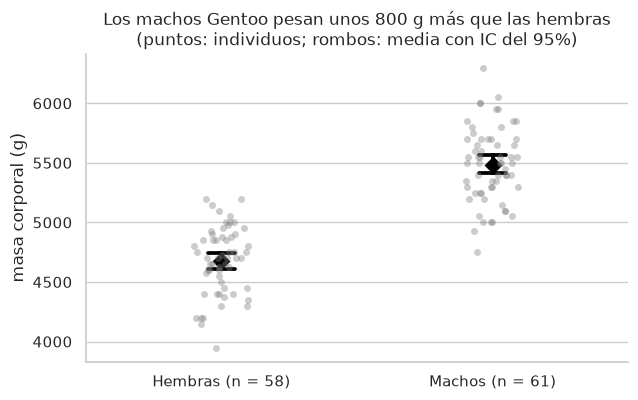

In [6]:
gentoo_con_sexo = gentoo.dropna(subset=["sex"]).assign(
    sexo=lambda d: d["sex"].map({"Female": f"Hembras (n = {len(hembras)})", "Male": f"Machos (n = {len(machos)})"}))
orden = [f"Hembras (n = {len(hembras)})", f"Machos (n = {len(machos)})"]
fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(gentoo_con_sexo, x="sexo", y="body_mass_g", order=orden, alpha=0.4, color="gray", ax=ax)
sns.pointplot(gentoo_con_sexo, x="sexo", y="body_mass_g", order=orden, errorbar=("ci", 95), color="black",
              linestyle="none", markers="D", capsize=0.1, seed=401, ax=ax)
ax.set(xlabel="", ylabel="masa corporal (g)",
       title="Los machos Gentoo pesan unos 800 g más que las hembras\n(puntos: individuos; rombos: media con IC del 95%)")
sns.despine()
plt.show()

**Interpretación:** la gráfica muestra en un solo vistazo la magnitud (la distancia entre rombos), la incertidumbre (los intervalos, muy cortos frente a la diferencia), la dispersión de los individuos y el traslape (pocas hembras superan a los machos más ligeros). **Error común que se evita:** la "gráfica de dinamita" (barra con la media y bigote de error), que esconde la distribución y el *n*.

### 2.3 Qué no afirmar.

| Tentación | Por qué no | Alternativa |
|---|---|---|
| Lenguaje causal ("provoca", "hace que", "el efecto de") con datos observacionales | No se controló la asignación; puede haber confusores | "Se asocia con", "tiende a", "en estos datos" |
| Generalizar a otra población | La muestra solo representa la población del marco | "En los modelos vendidos en EE. UU. de 1970 a 1982…" |
| "No hay diferencia" porque *p* > 0.05 | Ausencia de evidencia no es evidencia de ausencia | Reportar el IC: qué diferencias siguen siendo compatibles |
| Reportar solo lo significativo | Es *p-hacking* (sesión 6) | Reportar todas las pruebas que se hicieron |
| Precisión falsa (805.0954 g) | Sugiere una exactitud que el IC desmiente | Redondear según el ancho del IC |

**💡 Ideas clave de la sección 2:**
* Cada hallazgo responde ¿cuánto?, ¿con qué seguridad? y ¿importa?
* El tamaño del efecto se traduce a frecuencias naturales (probabilidad de superioridad).
* La gráfica final tiene título con el hallazgo, unidades, datos, IC y *n*.
* Sin lenguaje causal ni generalizaciones fuera de la población.

---
## 3. Del *notebook* al informe: `nbconvert` (15 min).

`nbconvert` transforma un `.ipynb` en otros formatos. Desde la terminal del *Codespace*:

```
jupyter nbconvert --to html --no-input <notebook>.ipynb
jupyter nbconvert --to webpdf --no-input <notebook>.ipynb
```

Donde:
* `--to html` genera un HTML autocontenido (con las gráficas incrustadas) que se abre en cualquier navegador.
* `--to webpdf` genera un PDF a partir del HTML. Requiere instalar una vez `pip install "nbconvert[webpdf]"` y `playwright install chromium`. `--to pdf` usa LaTeX, que no viene en el *Codespace*.
* `--no-input` oculta las celdas de código y deja solo el Markdown y las salidas: es lo que se entrega como **informe**. Sin esa opción se exporta el análisis completo.
* `--execute` vuelve a ejecutar el *notebook* antes de exportar: una forma rápida de verificar la reproducibilidad.

**Ejemplo:** la misma conversión se puede hacer desde *Python* con `HTMLExporter`. Se armará un *notebook* mínimo con el resumen y una tabla, y se exportará a una carpeta temporal para no dejar archivos en el repositorio.

* La siguiente celda creará un *notebook* mínimo con `nbformat`, lo exportará a HTML con y sin código, y comparará el tamaño de ambos y si el código aparece en cada uno.

In [7]:
informe_demo = nbformat.v4.new_notebook()
informe_demo.cells = [
    nbformat.v4.new_markdown_cell("# Informe de prueba.\n\n" + resumen_mpg),
    nbformat.v4.new_code_cell("print('consumo mediano por origen (L/100 km): usa 12.7, europe 8.9, japan 7.4')"),
]
informe_demo.cells[1].outputs = [nbformat.v4.new_output("stream", name="stdout",
                                 text="consumo mediano por origen (L/100 km): usa 12.7, europe 8.9, japan 7.4\n")]
resultados_exportacion = {}
with tempfile.TemporaryDirectory() as carpeta:
    for ocultar_codigo in [False, True]:
        exportador = HTMLExporter(exclude_input=ocultar_codigo)
        html, _ = exportador.from_notebook_node(informe_demo)
        ruta_html = os.path.join(carpeta, f"informe_sin_codigo_{ocultar_codigo}.html")
        with open(ruta_html, "w", encoding="utf-8") as archivo:
            archivo.write(html)
        resultados_exportacion["sin código" if ocultar_codigo else "con código"] = {
            "kB": round(os.path.getsize(ruta_html) / 1024, 1),
            "¿aparece el código?": ">print</span>" in html,
            "¿aparece la salida?": "usa 12.7" in html,
        }
pd.DataFrame(resultados_exportacion).T

,kB,¿aparece el código?,¿aparece la salida?
con código,272.1,True,True
sin código,271.5,False,True


**Interpretación:** las dos versiones contienen el texto y la salida; solo la versión **con código** contiene la instrucción `print` (en el HTML el código aparece resaltado con etiquetas `<span>`, por eso se busca `>print</span>`). Ambos HTML pesan cientos de kB porque incluyen los estilos de *JupyterLab*. **Decisión que permite tomar:** se entrega el HTML **sin código** como informe y el `.ipynb` ejecutado como análisis, tal como pide la consigna del proyecto.

**Errores comunes que se evitan:**
* Exportar un *notebook* que no se ejecutó completo: el HTML muestra salidas viejas o vacías. Siempre **Restart & Run All** antes de exportar.
* Celdas de Markdown que solo tienen sentido junto al código ("la siguiente celda…"): en el informe sin código se leen raras. Redacta el informe en una sección final propia.

**💡 Ideas clave de la sección 3:**
* `jupyter nbconvert --to html --no-input` produce el informe; `--to webpdf` lo convierte a PDF.
* Se exporta solo después de **Restart & Run All**.

---
## 4. Taller de redacción y revisión entre pares (30 min).

**Lista de verificación para revisar el informe de un compañero:**

| # | Pregunta | Sí / No |
|---|---|---|
| 1 | ¿El resumen ejecutivo tiene 150 palabras o menos y dice **qué se encontró**, con números? | |
| 2 | ¿Se describe de dónde vienen los datos y a qué población representan? | |
| 3 | ¿Cada decisión de limpieza dice cuántas filas afecta? | |
| 4 | ¿Cada hallazgo tiene estimación, IC y tamaño del efecto? | |
| 5 | ¿Se revisaron los supuestos de cada prueba? | |
| 6 | ¿Las gráficas finales tienen título con el hallazgo, unidades y *n*? | |
| 7 | ¿Hay frases causales o generalizaciones injustificadas? | |
| 8 | ¿Las limitaciones mencionan sesgos y confusores concretos? | |
| 9 | ¿El *notebook* corre con **Restart & Run All**? | |

**Cómo dar retroalimentación:** una fortaleza concreta, los dos cambios más importantes (no veinte) y una pregunta que el informe no responde.

### 🟢 Ejercicio 1 · Resumen ejecutivo de tu proyecto.

**🎯 Objetivo:** redactar la pieza más leída del informe. **Qué se espera aprender:** a condensar el análisis en una respuesta con números, incertidumbre y límites, en máximo 150 palabras.

Escribe en `resumen_proyecto` el resumen ejecutivo de tu proyecto y verifica su extensión con `contar_palabras`. Si todavía no tienes resultados, escribe la estructura con marcadores (`[número]`) y complétala después.

* La siguiente celda muestra una solución posible.

In [8]:
resumen_proyecto = (
    "Se analizaron 53,940 diamantes del dataset diamonds para saber cómo se relaciona el precio con el peso y "
    "con la calidad del corte. El precio crece de forma casi lineal con el peso en escala logarítmica: un "
    "diamante con 10% más quilates cuesta en promedio [número]% más (IC 95%: [a] a [b]). Los cortes Ideal "
    "tienen un precio mediano menor que los Premium, pero también son más pequeños: a igual peso, la "
    "diferencia se invierte y es pequeña ([tamaño del efecto]). Principal limitación: los datos son de un "
    "solo vendedor y no incluyen la fecha de venta."
)
contar_palabras(resumen_proyecto)

97

**✅ Respuesta sugerida:**

Ejemplo con `diamonds` (97 palabras, con marcadores donde irán los números): sigue la misma estructura que el de `mpg`, es decir, qué se analizó, la respuesta a cada pregunta con su número y su IC, el confusor (el peso) y la limitación principal.

### 🟢 Ejercicio 2 · Un hallazgo completo.

**🎯 Objetivo:** producir un hallazgo con todas sus piezas. **Qué se espera aprender:** a encadenar estimación, IC, tamaño del efecto, gráfica final e interpretación en lenguaje llano.

Con `autos`, redacta el hallazgo "los modelos de EE. UU. consumen más que los japoneses": calcula la diferencia de **medianas** de `litros_100km` con su IC *bootstrap* percentil del 95% (`random_state=401`), la probabilidad de superioridad y una gráfica final que cumpla la lista de la sección 2.2. Termina con una frase en lenguaje llano que mencione el confusor.

* La siguiente celda muestra una solución posible.

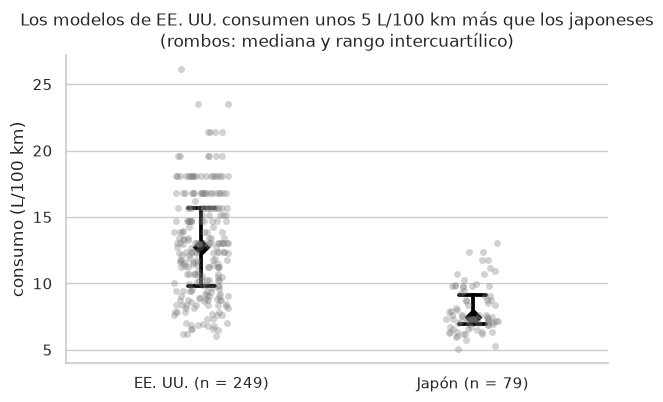

{'diferencia de medianas': 5.27,
 'IC 95%': (4.41, 5.72),
 'probabilidad de superioridad': 0.873}

In [9]:
consumo_usa = autos.loc[autos["origin"] == "usa", "litros_100km"].to_numpy()
consumo_japon = autos.loc[autos["origin"] == "japan", "litros_100km"].to_numpy()


def diferencia_medianas(a, b, axis=-1):
    return np.median(a, axis=axis) - np.median(b, axis=axis)


ic_origen = stats.bootstrap((consumo_usa, consumo_japon), diferencia_medianas, n_resamples=9999,
                            method="percentile", random_state=401).confidence_interval
superioridad = stats.mannwhitneyu(consumo_usa, consumo_japon).statistic / (len(consumo_usa) * len(consumo_japon))

dos_origenes = autos[autos["origin"].isin(["usa", "japan"])].assign(
    origen=lambda d: d["origin"].map({"usa": f"EE. UU. (n = {len(consumo_usa)})", "japan": f"Japón (n = {len(consumo_japon)})"}))
fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(dos_origenes, x="origen", y="litros_100km", alpha=0.35, color="gray", ax=ax)
sns.pointplot(dos_origenes, x="origen", y="litros_100km", estimator="median", errorbar=("pi", 50), color="black",
              linestyle="none", markers="D", capsize=0.1, ax=ax)
ax.set(xlabel="", ylabel="consumo (L/100 km)",
       title="Los modelos de EE. UU. consumen unos 5 L/100 km más que los japoneses\n(rombos: mediana y rango intercuartílico)")
sns.despine()
plt.show()
{"diferencia de medianas": round(float(diferencia_medianas(consumo_usa, consumo_japon)), 2),
 "IC 95%": (round(float(ic_origen.low), 2), round(float(ic_origen.high), 2)),
 "probabilidad de superioridad": round(float(superioridad), 3)}

**✅ Respuesta sugerida:**

La mediana del consumo de los modelos de EE. UU. es unos 5.3 L/100 km mayor que la de los japoneses (IC 95% *bootstrap*: alrededor de 4.4 a 5.7 L/100 km), y en cerca de 87 de cada 100 pares EE. UU.-Japón el modelo estadounidense consume más. **En lenguaje llano:** "Los modelos de EE. UU. de 1970 a 1982 consumían bastante más combustible que los japoneses, pero también eran mucho más pesados; entre autos de peso parecido la diferencia es menor de 1 L/100 km (sesión 7), así que buena parte de la brecha refleja el tamaño de los autos, no su origen."

### 🟢 Ejercicio 3 · Corrige las frases.

**🎯 Objetivo:** detectar afirmaciones que los datos no respaldan. **Qué se espera aprender:** a revisar un informe (propio o ajeno) con la tabla de la sección 2.3.

Reescribe cada frase para que sea correcta:
1. "El origen japonés hace que los autos consuman menos."
2. "La prueba de Welch demostró con 99.9% de certeza que los machos Adelie pesan más."
3. "Como *p* = 0.59, los Chinstrap y los Adelie pesan lo mismo."
4. "La correlación de 0.89 indica que 89% del consumo se debe al peso."

**✅ Respuesta sugerida:**

1. "Los modelos japoneses consumían menos en promedio, pero también eran más ligeros; a igual peso la diferencia casi desaparece." (Lenguaje causal y confusor omitido.)
2. "Los machos Adelie pesaron en promedio unos 675 g más (IC 95%: 573 a 776 g); una diferencia así sería muy improbable si los sexos no difirieran (*p* < 0.001)." (El valor *p* no es una certeza.)
3. "No se encontró evidencia de diferencia de masa entre Chinstrap y Adelie; los datos son compatibles con diferencias de −86 a 150 g." (No rechazar H0 no demuestra igualdad.)
4. "Los autos más pesados tienden a consumir más; la relación es fuerte (*r* = 0.89)." Si se quiere una proporción, $r^2 \approx 0.78$ es la fracción de la **variabilidad** del consumo asociada linealmente con el peso, no la fracción del consumo "causada" por el peso.

### 🔴 Reto 1 · Exporta tu propio informe.

**🎯 Objetivo:** practicar la exportación real que se entregará. **Qué se espera aprender:** a detectar, en el HTML, lo que se lee mal sin el código.

En la terminal del *Codespace*, exporta tu copia de la plantilla del proyecto a HTML **sin código** con `jupyter nbconvert --to html --no-input`. Ábrelo en el navegador y anota tres cosas que se leen mal sin el código (frases como "la siguiente celda…", tablas sin título, gráficas sin unidades). Corrígelas en el *notebook* y vuelve a exportar.

**✅ Respuesta sugerida:**

Problemas típicos: celdas de Markdown que remiten al código ("como se ve arriba"), salidas largas de `describe()` sin una frase que diga qué mirar, gráficas exploratorias que no se eliminaron y títulos genéricos. La solución es que la sección **Informe** de la plantilla se pueda leer sola, con sus propias tablas resumidas y gráficas finales.

### 🔴 Reto 2 · Probabilidad de superioridad e incertidumbre.

**🎯 Objetivo:** acompañar el tamaño del efecto con su propia incertidumbre. **Qué se espera aprender:** que cualquier estadístico, incluso uno "para el público", tiene un IC.

Calcula un IC *bootstrap* percentil del 95% (`random_state=401`) para la probabilidad de superioridad de los machos sobre las hembras **Adelie** en masa corporal. Redacta la frase en lenguaje llano.

* La siguiente celda muestra una solución posible.

In [10]:
adelie = pinguinos[pinguinos["species"] == "Adelie"]
machos_adelie = adelie.loc[adelie["sex"] == "Male", "body_mass_g"].to_numpy()
hembras_adelie = adelie.loc[adelie["sex"] == "Female", "body_mass_g"].to_numpy()


def prob_superioridad(a, b, axis=-1):
    a, b = np.moveaxis(a, axis, -1), np.moveaxis(b, axis, -1)
    mayor = (a[..., :, None] > b[..., None, :]).mean(axis=(-2, -1))
    empate = (a[..., :, None] == b[..., None, :]).mean(axis=(-2, -1))
    return mayor + 0.5 * empate


ic_ps = stats.bootstrap((machos_adelie, hembras_adelie), prob_superioridad, n_resamples=1999, method="percentile",
                        random_state=401, batch=200).confidence_interval
round(float(prob_superioridad(machos_adelie, hembras_adelie)), 3), (round(float(ic_ps.low), 3), round(float(ic_ps.high), 3))

(0.942, (0.907, 0.971))

**✅ Respuesta sugerida:**

La probabilidad de superioridad es 0.942 (IC 95% *bootstrap* aproximadamente de 0.91 a 0.97). **En lenguaje llano:** "Al comparar un macho y una hembra Adelie elegidos al azar, el macho pesa más en unos 94 de cada 100 casos (entre 91 y 97, con 95% de confianza)." Se usan 1,999 remuestras y `batch=200` para limitar la memoria, porque cada remuestra compara todos los pares.

---
## 5. Presentaciones relámpago, Evaluación semanal 2 y cierre del curso (20 min).

### 5.1 Presentaciones relámpago (voluntarias, 3 min).

Estructura sugerida: (1) la pregunta en una frase, (2) **una** gráfica final, (3) el hallazgo con su número e incertidumbre, (4) la principal limitación. Sin código en pantalla.

### 5.2 📣 Evaluación semanal 2.

**Se publica hoy en Classroom** (el texto siguiente es la referencia). **Publicación:** jueves 29 de octubre, 8:30 pm · **Cierre:** domingo 1 de noviembre, 11:59 pm (CDMX). Entregas tardías: se **sugiere** aceptarlas hasta 48 h después con 10% de penalización, pero no es una regla del curso; el instructor confirmará en Classroom si se aplica.

**Formato (100 puntos):**
* **Cuestionario (30 puntos):** Google Forms en modo examen, 10 preguntas de 3 puntos, calificación automática, un intento. Cubre los módulos III y IV (sesiones 5 a 8).
* **Proyecto integrador (70 puntos):** tarea de Classroom con la consigna y la rúbrica del *notebook* 05. Se entrega el `.ipynb` ejecutado, el informe (`.html` o `.pdf`) y el enlace al repositorio de GitHub.

**Preguntas de muestra** (para practicar; el cuestionario real tiene otras):
1. Un IC del 95% para la media significa que: a) hay 95% de probabilidad de que la media muestral esté en el intervalo; b) el procedimiento captura la media poblacional en 95% de las muestras repetidas; c) el 95% de los datos está en el intervalo; d) la hipótesis nula es falsa con 95% de certeza.
2. Al aumentar el tamaño de muestra de *n* a 4*n*, el error estándar de la media: a) se duplica; b) se reduce a la mitad; c) se reduce a la cuarta parte; d) no cambia.
3. El *bootstrap* estima la distribución muestral: a) suponiendo normalidad; b) remuestreando con reemplazo los datos observados; c) remuestreando sin reemplazo; d) recolectando datos nuevos.
4. Un valor *p* de 0.03 significa: a) que H0 tiene 3% de probabilidad de ser cierta; b) que, si H0 fuera cierta, un resultado al menos así de extremo ocurriría alrededor de 3% de las veces; c) que el efecto es grande; d) que el estudio tiene 97% de potencia.
5. Para comparar las medias de dos grupos independientes con varianzas distintas conviene: a) *t* pareada; b) *t* de Welch; c) chi cuadrada; d) correlación de Pearson.
6. Para probar si la clase del pasajero y la supervivencia son independientes se usa: a) ANOVA; b) *t* de Student; c) chi cuadrada de independencia; d) regresión lineal.
7. Un supuesto clave de la chi cuadrada es: a) que las frecuencias esperadas sean suficientemente grandes (≥ 5 en general); b) normalidad de los datos; c) igualdad de medias; d) datos pareados.
8. Un ANOVA con *p* < 0.05 entre 4 grupos indica: a) que los 4 grupos son distintos entre sí; b) que al menos un grupo difiere y se requiere una prueba *post hoc* (por ejemplo, Tukey) para saber cuáles; c) que el efecto es grande; d) que hay causalidad.
9. Con *n* = 100,000, una diferencia de medias tiene *p* < 0.001 y d de Cohen = 0.03. Lo correcto es concluir que: a) es un hallazgo muy importante; b) es estadísticamente significativa pero de magnitud prácticamente despreciable; c) es un error; d) hay que rechazar el resultado.
10. En un informe de hallazgos, un estudio observacional permite afirmar: a) "X causa Y"; b) "X se asocia con Y", señalando posibles confusores; c) "X no influye en Y" si *p* > 0.05; d) nada.

**✅ Respuesta sugerida:**

Respuestas: 1 b · 2 b · 3 b · 4 b · 5 b · 6 c · 7 a · 8 b · 9 b · 10 b. Cada una corresponde a una sección del curso: 1 y 2 (sesión 5, secciones 1 y 4), 3 (sesión 5, sección 3), 4, 5, 8 y 9 (sesión 6), 6 y 7 (sesión 6, sección 3), 10 (sesiones 4 y 8).

### 5.3 ✅ Cierre del curso.

**En el curso vimos:**
* **Módulo I:** *NumPy* y *pandas* 3, tipos de variables y escalas de medición, muestreo y sesgos, calidad de datos y faltantes.
* **Módulo II:** distribuciones, medidas robustas y atípicos; agregación, relaciones, confusores y visualización.
* **Módulo III:** distribución muestral, intervalos de confianza y *bootstrap*; pruebas de hipótesis y tamaño del efecto.
* **Módulo IV:** un EDA completo y reproducible, y su informe de hallazgos.

**Hoy vimos:** la estructura del informe, cómo traducir IC y tamaños del efecto a lenguaje llano, la gráfica final, qué no afirmar, la exportación con `nbconvert` y la revisión entre pares.

**Diploma:** calificación final = (E1 + E2) / 2 de al menos 70 y asistencia a al menos 7 de las 8 sesiones.

**Pendiente:** cuestionario y Proyecto integrador de la Evaluación semanal 2, antes del **domingo 1 de noviembre, 11:59 pm (CDMX)**. ¡Gracias por participar!

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>